## Exploratory Data Analysis (EDA)

In [2]:
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / 'data').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

# 1. Data Loading and Validation

### Data Loading

In [3]:
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'case_cc_fraud.csv'

if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Dataset does not exist: {DATA_PATH}')

df = pd.read_csv(
    DATA_PATH,
    dtype={
        'cc_num': 'string', 'zip': 'string',
        'merchant': 'category', 'category': 'category',
        'gender': 'category', 'state': 'category',
    },
)

print(f'Loaded {len(df):,} transactions.')

Loaded 1,852,394 transactions.


### Dataset Overview

In [4]:
print(f'Number of rows: {df.shape[0]:,}')
print(f'Number of columns: {df.shape[1]}')

pd.DataFrame({'column': df.columns, 'data type': df.dtypes.astype(str).values})

Number of rows: 1,852,394
Number of columns: 22


,column,data type
0,trans_date_trans_time,object
1,cc_num,string
2,merchant,category
3,category,category
4,amt,float64
5,first,object
6,last,object
7,gender,category
8,street,object
9,city,object


### Dates and Chronological Order

In [5]:
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'], errors='coerce')
time = df['trans_date_trans_time']
invalid_dates = int(time.isna().sum())

print('From:', time.min())
print('To:', time.max())
print('Missing or invalid dates:', invalid_dates)

if invalid_dates:
    print('Chronological order cannot be reliably checked.')
else:
    print('Chronologically sorted:', time.is_monotonic_increasing)

From: 2019-01-01 00:00:18
To: 2020-12-31 23:59:34
Missing or invalid dates: 0
Chronologically sorted: False


### Missing Values

In [6]:
missing = df.isna().sum()
pd.DataFrame({
    'missing values': missing,
    'percentage': missing / len(df) * 100,
})

,missing values,percentage
trans_date_trans_time,0,0.0
cc_num,0,0.0
merchant,0,0.0
category,0,0.0
amt,0,0.0
first,0,0.0
last,0,0.0
gender,0,0.0
street,0,0.0
city,0,0.0


### Duplicate Records

In [7]:
print(f'Duplicate rows: {df.duplicated().sum():,}')

df = df.drop_duplicates().copy()
conflicting_trans_num = df['trans_num'].duplicated(keep=False) & df['trans_num'].notna()

print(f'Rows with matching transaction numbers after removing exact duplicates: {conflicting_trans_num.sum():,}')
print(f'Matching transaction numbers to review: {df.loc[conflicting_trans_num, "trans_num"].nunique():,}')
print(f'Missing transaction number: {df["trans_num"].isna().sum():,}')
print(f'Rows after removing exact duplicates: {len(df):,}')

Duplicate rows: 0
Rows with matching transaction numbers after removing exact duplicates: 0
Matching transaction numbers to review: 0
Missing transaction number: 0
Rows after removing exact duplicates: 1,852,394


### Data Validation

In [8]:
dob = pd.to_datetime(df['dob'], errors='coerce')
unix_date = pd.to_datetime(df['unix_time'], unit='s', utc=True, errors='coerce').dt.tz_localize(None)
valid_coordinates = (
    df['lat'].between(-90, 90) & df['long'].between(-180, 180)
    & df['merch_lat'].between(-90, 90) & df['merch_long'].between(-180, 180)
)

checks = pd.Series({
    'Zero or negative amount': ((df['amt'] <= 0) & df['amt'].notna()).sum(),
    'Missing amount': df['amt'].isna().sum(),
    'Invalid or missing date of birth': dob.isna().sum(),
    'Missing or invalid coordinates': (~valid_coordinates).sum(),
    'Invalid or missing fraud label': (~df['is_fraud'].isin([0, 1])).sum(),
    'Invalid or missing unix_time': unix_date.isna().sum(),
})

display(checks.to_frame('count'))

,count
Zero or negative amount,0
Missing amount,0
Invalid or missing date of birth,0
Missing or invalid coordinates,0
Invalid or missing fraud label,0
Invalid or missing unix_time,0


# 2. Dataset Overview and Fraud Baseline

### Overall Fraud Rate and Dataset Imbalance

,count,percentage
is_fraud,,
0,1842743,99.478999
1,9651,0.521001


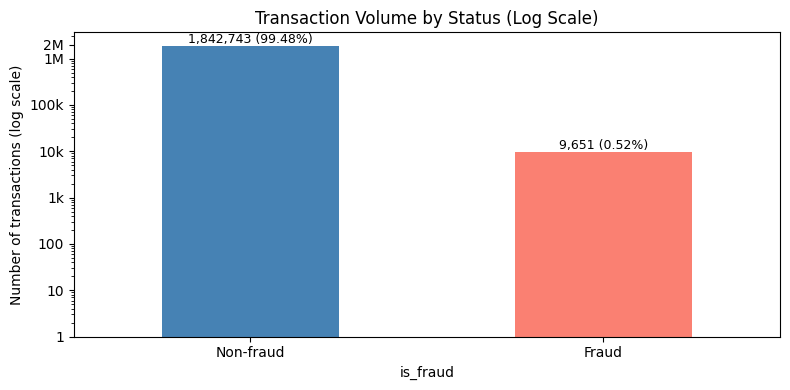

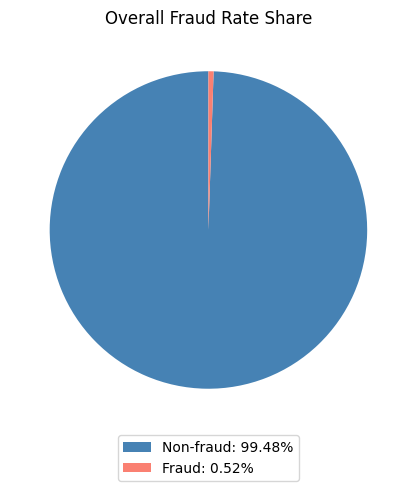

In [9]:
target = df['is_fraud'].value_counts().reindex([0, 1], fill_value=0)
target_table = pd.DataFrame({'count': target, 'percentage': target / target.sum() * 100})

display(target_table)

fig, ax = plt.subplots(figsize=(8, 4))
target.rename(index={0: 'Non-fraud', 1: 'Fraud'}).plot.bar(
    ax=ax, color=['steelblue', 'salmon']
)

for bar, count in zip(ax.patches, target):
    if count:
        ax.annotate(f'{count:,} ({count / target.sum() * 100:.2f}%)',
                    (bar.get_x() + bar.get_width() / 2, count),
                    ha='center', va='bottom', fontsize=9)
        
ax.set_yscale('log')
ax.set_ylim(1, max(10, target.max() * 2))
ticks = [tick for tick in [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 2_000_000]
         if tick <= max(10, target.max() * 2)]
ax.set_yticks(ticks)
ax.set_yticklabels([
    f'{tick / 1_000_000:g}M' if tick >= 1_000_000
    else f'{tick / 1_000:g}k' if tick >= 1_000 else str(tick)
    for tick in ticks
])
ax.set_ylabel('Number of transactions (log scale)')
ax.set_title('Transaction Volume by Status (Log Scale)')
ax.tick_params(axis='x', labelrotation=0)
plt.tight_layout()
plt.show()

fig, pie_ax = plt.subplots(figsize=(6, 5))
pie_ax.pie(target, colors=['steelblue', 'salmon'], startangle=90)
pie_ax.legend(
    [f'Non-fraud: {target_table.loc[0, "percentage"]:.2f}%',
     f'Fraud: {target_table.loc[1, "percentage"]:.2f}%'],
    loc='lower center', bbox_to_anchor=(0.5, -0.15)
)
pie_ax.set_title('Overall Fraud Rate Share')
plt.tight_layout()
plt.show()

The dataset exhibits a strong class imbalance, where fraudulent transactions account for only a small fraction (approximately 0.52%) of the total data volume.

### Cards and Merchants

In [10]:
cards = df['cc_num'].nunique()

print(f'Unique cards: {cards:,}')
print(f'Unique merchants: {df["merchant"].nunique():,}')
print(f'Average transactions per card: {len(df) / cards:,.1f}')

Unique cards: 999
Unique merchants: 693
Average transactions per card: 1,854.2


### Card-Level Fraud Distribution

In [11]:
card_frauds = df.groupby('cc_num', observed=True)['is_fraud'].sum()

print('Cards with at least one fraud:', int((card_frauds > 0).sum()))
print('Cards without fraud:', int((card_frauds == 0).sum()))
print('Missing card numbers:', int(df['cc_num'].isna().sum()))

card_frauds[card_frauds > 0].describe(percentiles=[0.5, 0.9, 0.99]).to_frame('frauds per card')

Cards with at least one fraud: 976
Cards without fraud: 23
Missing card numbers: 0


,frauds per card
count,976.000000
mean,9.888320
std,2.983859
min,2.000000
50%,10.000000
90%,14.000000
99%,16.000000
max,19.000000


# 3. Time-Based Analysis

### Monthly Transaction Trends and Fraud Rate Evolution

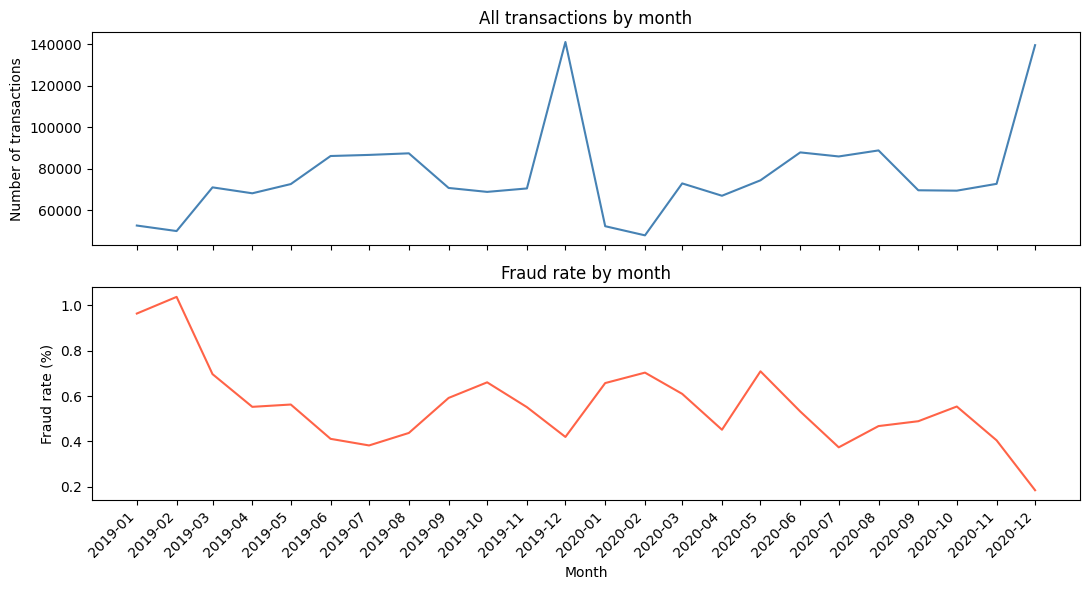

In [12]:
monthly = df.set_index('trans_date_trans_time').resample('MS')['is_fraud'].agg(['count', 'sum', 'mean'])
monthly.columns = ['transactions', 'frauds', 'fraud_rate']

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(monthly.index, monthly['transactions'], color='steelblue')
axes[0].set_title('All transactions by month')
axes[0].set_ylabel('Number of transactions')
axes[1].plot(monthly.index, monthly['fraud_rate'] * 100, color='tomato')
axes[1].set_title('Fraud rate by month')
axes[1].set_ylabel('Fraud rate (%)')
axes[1].set_xlabel('Month')
axes[1].set_xticks(monthly.index)
axes[1].set_xticklabels(monthly.index.strftime('%Y-%m'), rotation=45, ha='right')
plt.tight_layout()
plt.show()


The temporal analysis shows seasonal fluctuations in transaction volume, highlighting a sharp increase in December (corresponding to holiday shopping), indicating that an increase in overall transaction volume does not necessarily translate to a proportional rise in fraud.

### Hourly Risk Concentration


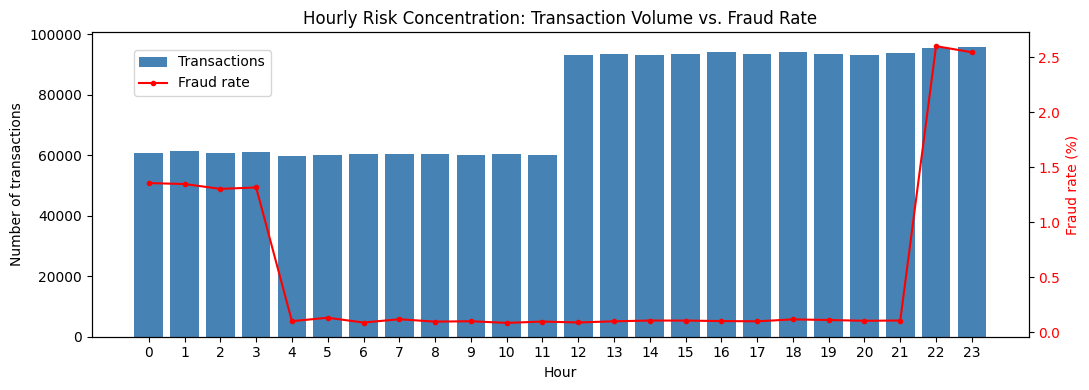

,transactions,frauds,fraud rate
hour,,,
0,60655,823,0.013569
1,61330,827,0.013484
2,60796,793,0.013044
3,60968,803,0.013171
4,59938,61,0.001018
5,60088,80,0.001331
6,60406,54,0.000894
7,60301,72,0.001194
8,60498,59,0.000975


In [13]:
df['hour'] = df['trans_date_trans_time'].dt.hour
hourly = df.groupby('hour')['is_fraud'].agg(['count', 'sum', 'mean']).reindex(range(24))
hourly[['count', 'sum']] = hourly[['count', 'sum']].fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(hourly.index, hourly['count'], color='steelblue', label='Transactions')
ax.set_xlabel('Hour')
ax.set_ylabel('Number of transactions')
ax.set_xticks(range(24))

rate_ax = ax.twinx()
rate_ax.plot(hourly.index, hourly['mean'] * 100, color='red', marker='o',
             markersize=3, label='Fraud rate')
rate_ax.set_ylabel('Fraud rate (%)', color='red')
rate_ax.tick_params(axis='y', labelcolor='red')
ax.set_title('Hourly Risk Concentration: Transaction Volume vs. Fraud Rate')
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

hourly.rename(columns={'count': 'transactions', 'sum': 'frauds', 'mean': 'fraud rate'})


The hourly distribution analysis reveals a pronounced concentration of fraud during nighttime hours (particularly between 22:00 and 03:00), where the fraud rate peaks significantly despite a relatively low overall transaction volume at that time.

### Weekly Risk Profile

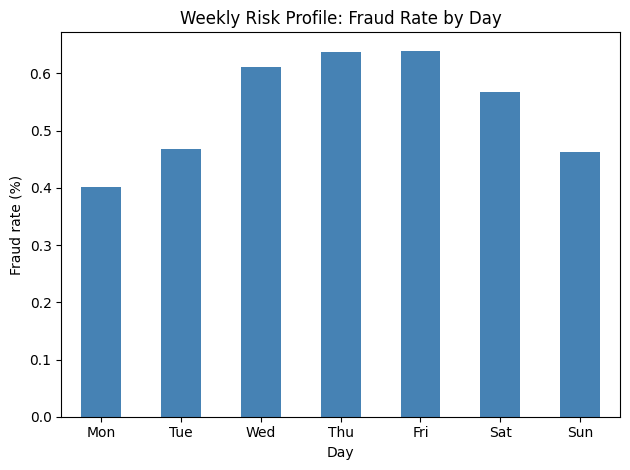

,transactions,frauds,fraud rate
Mon,369418,1484,0.004017
Tue,270340,1266,0.004683
Wed,183913,1125,0.006117
Thu,206741,1317,0.006370
Fri,215078,1376,0.006398
Sat,263227,1493,0.005672
Sun,343677,1590,0.004626


In [14]:
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
daily = df.groupby('day_of_week')['is_fraud'].agg(['count', 'sum', 'mean']).reindex(range(7))

daily.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
(daily['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Day')
plt.ylabel('Fraud rate (%)')
plt.title('Weekly Risk Profile: Fraud Rate by Day')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

daily.rename(columns={'count': 'transactions', 'sum': 'frauds', 'mean': 'fraud rate'})

The fraud rate shows moderate weekly variability, with slightly higher risk concentrated mid-to-late week (Wednesday through Friday).

### Interaction of Hours and Days of the Week


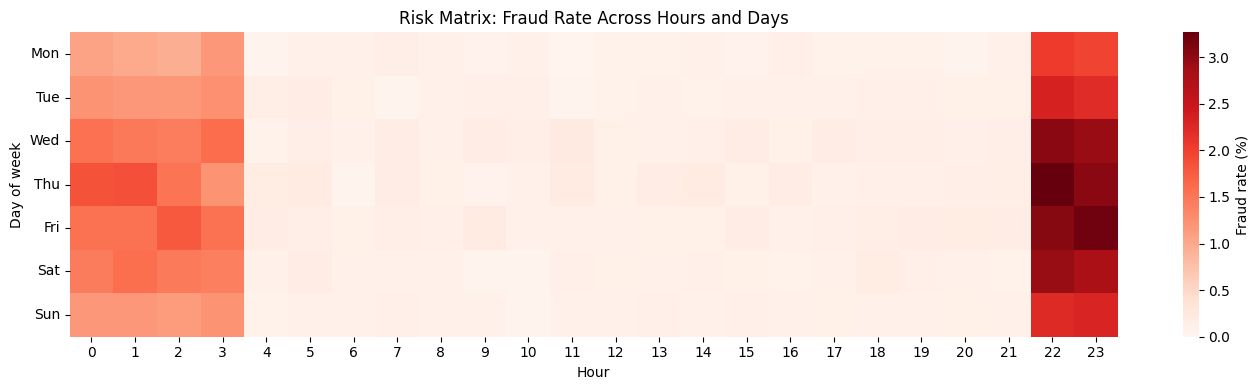

In [15]:
time_stats = df.groupby(['day_of_week', 'hour'])['is_fraud'].agg(['count', 'mean'])
fraud_by_time = (time_stats['mean'].unstack('hour') * 100).reindex(index=range(7), columns=range(24))
time_counts = time_stats['count'].unstack('hour').reindex(index=range(7), columns=range(24), fill_value=0).fillna(0).astype(int)
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fraud_by_time.index = days
time_counts.index = days

plt.figure(figsize=(14, 4))
sns.heatmap(fraud_by_time, cmap='Reds', vmin=0, cbar_kws={'label': 'Fraud rate (%)'})
plt.xlabel('Hour')
plt.ylabel('Day of week')
plt.title('Risk Matrix: Fraud Rate Across Hours and Days')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



The combined risk matrix confirms previous observations, showing that the highest fraud concentration occurs across all days of the week primarily during nighttime hours, with peak intensity observed mid-to-late week (Wednesday through Friday)

# 4. Fraud Drivers & Risk Analysis

### Transaction Amount


,count,mean,std,min,50%,90%,99%,max
is_fraud,,,,,,,,
0,1842743.0,67.651278,153.548108,1.00,47.24,134.17,484.91,28948.90
1,9651.0,530.661412,391.028873,1.06,390.00,1024.61,1175.85,1376.04


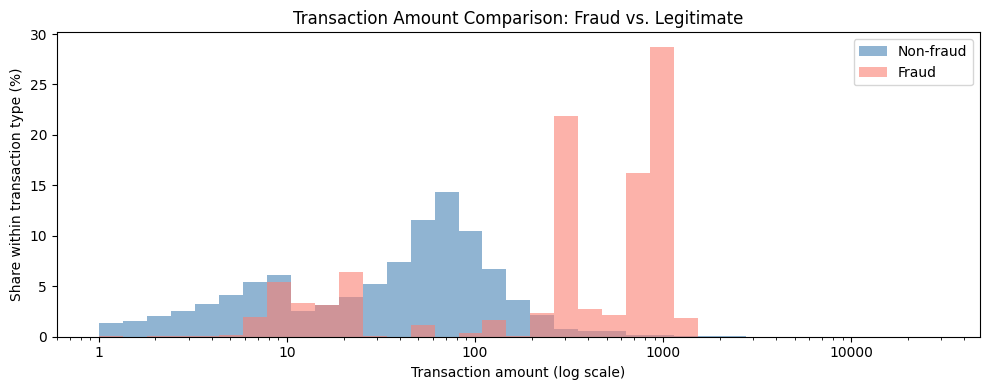

In [16]:
display(df.groupby('is_fraud')['amt'].describe(percentiles=[0.5, 0.9, 0.99]))

valid_amount = df['amt'].notna() & np.isfinite(df['amt']) & (df['amt'] > 0)

positive_amounts = df.loc[valid_amount, 'amt']

if positive_amounts.empty:
    raise ValueError('There are no positive, finite transaction amounts to plot.')

lower, upper = positive_amounts.min(), positive_amounts.max()

if lower == upper:
    lower, upper = lower / 2, upper * 2

bins = np.geomspace(lower, upper, 36)
bins[0], bins[-1] = lower, upper

plt.figure(figsize=(10, 4))

for label, name, color in [(0, 'Non-fraud', 'steelblue'), (1, 'Fraud', 'salmon')]:
    amounts = df.loc[valid_amount & (df['is_fraud'] == label), 'amt']
    if not amounts.empty:
        weights = np.full(len(amounts), 100 / len(amounts))
        plt.hist(amounts, bins=bins, weights=weights, color=color, alpha=0.6, label=name)

plt.xscale('log')
plt.gca().xaxis.set_major_formatter(ScalarFormatter())
plt.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.xlabel('Transaction amount (log scale)')
plt.ylabel('Share within transaction type (%)')
plt.title('Transaction Amount Comparison: Fraud vs. Legitimate')
plt.legend()
plt.tight_layout()
plt.show()


The distribution comparison on a log scale reveals that while legitimate payments exhibit a smoother distribution around moderate amounts, fraudulent transactions show a pattern with clustering in two distinct ranges, lower values and particularly higher amounts.

### Fraud Rate by Amount Brackets

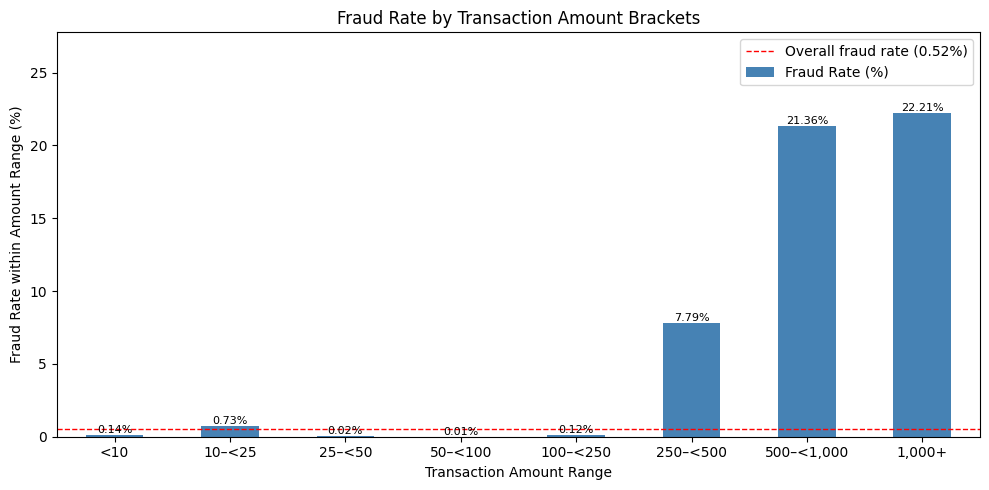

,count,sum,mean,fraud_rate_pct
amt,,,,
<10,479859,672,0.001400,0.140041
10–<25,182666,1326,0.007259,0.725915
25–<50,298572,71,0.000238,0.023780
50–<100,556349,63,0.000113,0.011324
100–<250,281025,327,0.001164,0.116360
250–<500,32214,2508,0.077854,7.785435
"500–<1,000",16189,3458,0.213602,21.360183
"1,000+",5520,1226,0.222101,22.210145


In [17]:
amount_group = pd.cut(
    df.loc[valid_amount, 'amt'],
    bins=[0, 10, 25, 50, 100, 250, 500, 1000, np.inf],
    labels=['<10', '10–<25', '25–<50', '50–<100', '100–<250',
            '250–<500', '500–<1,000', '1,000+'],
    right=False,
)

amount_stats = df.loc[valid_amount].groupby(amount_group, observed=False)['is_fraud'].agg(['count', 'sum', 'mean'])
amount_stats['fraud_rate_pct'] = amount_stats['sum'] / amount_stats['count'].replace(0, np.nan) * 100
baseline = df['is_fraud'].mean() * 100

ax = amount_stats['fraud_rate_pct'].plot.bar(color='steelblue', figsize=(10, 5), rot=0, label='Fraud Rate (%)')

for i, rate in enumerate(amount_stats['fraud_rate_pct']):
    if pd.notna(rate):
        ax.text(i, rate, f'{rate:.2f}%', ha='center', va='bottom', fontsize=8)

ax.axhline(baseline, color='red', linestyle='--', linewidth=1,
           label=f'Overall fraud rate ({baseline:.2f}%)')
max_rate = max(amount_stats['fraud_rate_pct'].max(), baseline)
ax.set_ylim(0, max(1, max_rate * 1.25))
ax.set_xlabel('Transaction Amount Range')
ax.set_ylabel('Fraud Rate within Amount Range (%)')
ax.set_title('Fraud Rate by Transaction Amount Brackets')
ax.legend()
plt.tight_layout()
plt.show()

display(amount_stats)


The transaction amount bracket analysis confirms the previous observation, showing that the relative risk rate increases sharply in higher value brackets, significantly exceeding the overall dataset average.

### Distance Between Customer and Merchant

In [18]:
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1
    
    a = np.sin(delta_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2

    return 2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

In [19]:
df['distance_km'] = haversine_km(
    df['lat'].to_numpy(), df['long'].to_numpy(),
    df['merch_lat'].to_numpy(), df['merch_long'].to_numpy(),
)

df.loc[~valid_coordinates, 'distance_km'] = np.nan


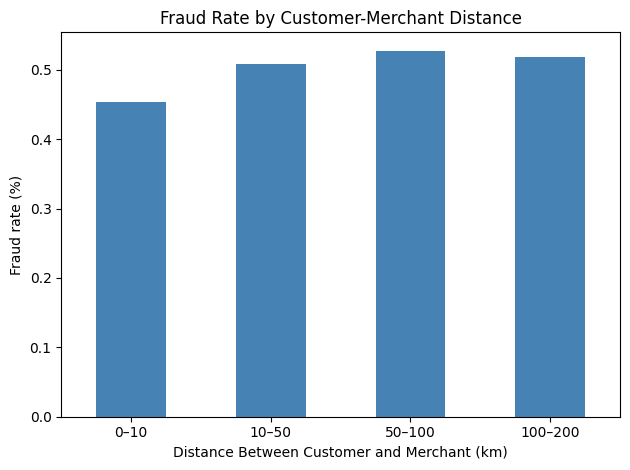

,transactions,frauds,fraud rate
distance_km,,,
0–10,14981,68,0.004539
10–50,363938,1850,0.005083
50–100,1040793,5491,0.005276
100–200,432682,2242,0.005182


In [20]:
distance_group = pd.cut(df['distance_km'], bins=[0, 10, 50, 100, 200, np.inf],
                        labels=['0–10', '10–50', '50–100', '100–200', '200+'],
                        right=False)

distance_stats = df.groupby(distance_group, observed=True)['is_fraud'].agg(['count', 'sum', 'mean'])
(distance_stats['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Distance Between Customer and Merchant (km)')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud Rate by Customer-Merchant Distance')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

distance_stats.rename(columns={'count': 'transactions', 'sum': 'frauds', 'mean': 'fraud rate'})

The analysis of customer-to-merchant distance shows only marginal variations in risk rate across brackets, suggesting that geographic distance alone may not act as a strong independent predictor of fraud.

### Fraud Rate Concentration by Merchant Category

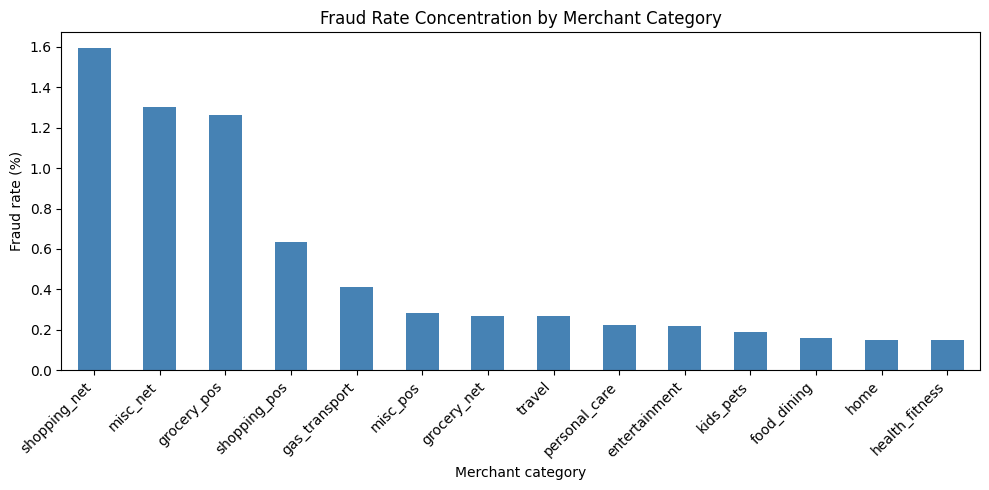

,mean,count,sum
category,,,
shopping_net,0.015927,139322,2219
misc_net,0.013039,90654,1182
grocery_pos,0.012645,176191,2228
shopping_pos,0.006344,166463,1056
gas_transport,0.004106,188029,772
misc_pos,0.002819,114229,322
grocery_net,0.002697,64878,175
travel,0.002692,57956,156
personal_care,0.002229,130085,290


In [21]:
category_stats = df.groupby('category', observed=True)['is_fraud'].agg(['mean', 'count', 'sum'])

(category_stats['mean'].sort_values(ascending=False) * 100).plot.bar(color='steelblue', figsize=(10, 5))
plt.xlabel('Merchant category')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud Rate Concentration by Merchant Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

category_stats.sort_values('mean', ascending=False)


The risk rate varies significantly by merchant category, with online shopping categories exhibiting the highest fraud concentration compared to most physical POS transactions.

### Median Fraud Transaction Value by Merchant Category

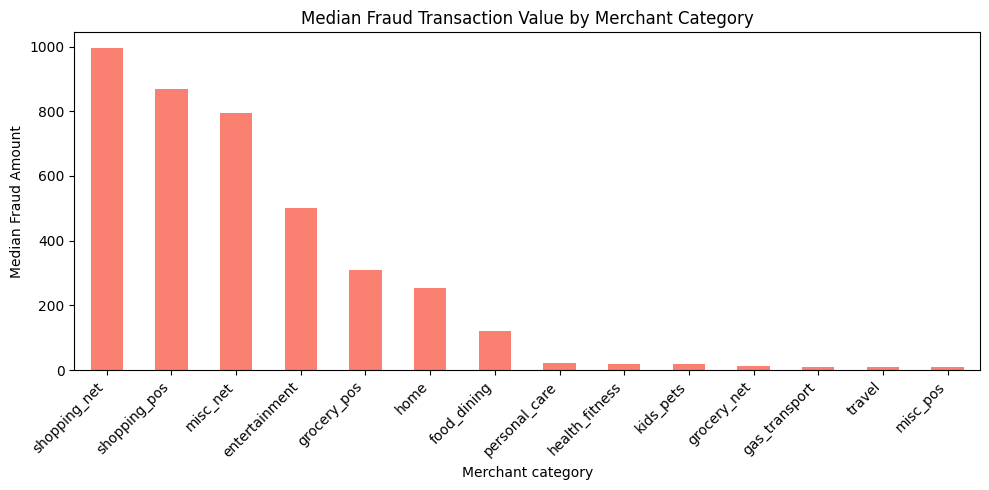

,count,median,sum
category,,,
grocery_pos,2228,310.235,695664.62
shopping_net,2219,994.150,2214847.64
misc_net,1182,794.215,944009.71
shopping_pos,1056,869.915,928132.34
gas_transport,772,10.640,9442.53
misc_pos,322,9.100,68494.84
kids_pets,304,19.645,5619.53
entertainment,292,500.835,147399.96
personal_care,290,20.970,7571.96


In [22]:
fraud_amount = df.loc[df['is_fraud'] == 1].groupby('category', observed=True)['amt'].median()

fraud_amount.sort_values(ascending=False).plot.bar(color='salmon', figsize=(10, 5))

plt.xlabel('Merchant category')
plt.ylabel('Median Fraud Amount')
plt.xticks(rotation=45, ha='right')
plt.title('Median Fraud Transaction Value by Merchant Category')
plt.tight_layout()
plt.show()

fraud_amount_counts = df.loc[df['is_fraud'] == 1].groupby('category', observed=True)['amt'].agg(['count', 'median', 'sum'])
fraud_amount_counts.sort_values('count', ascending=False)

While fraud amounts in everyday categories (transportation, services) remain negligible, shopping-related segments (both online and physical POS) sustain high median values, identifying shopping as the primary driver of financial loss exposure.

### Total Fraud Amount by Merchant Category


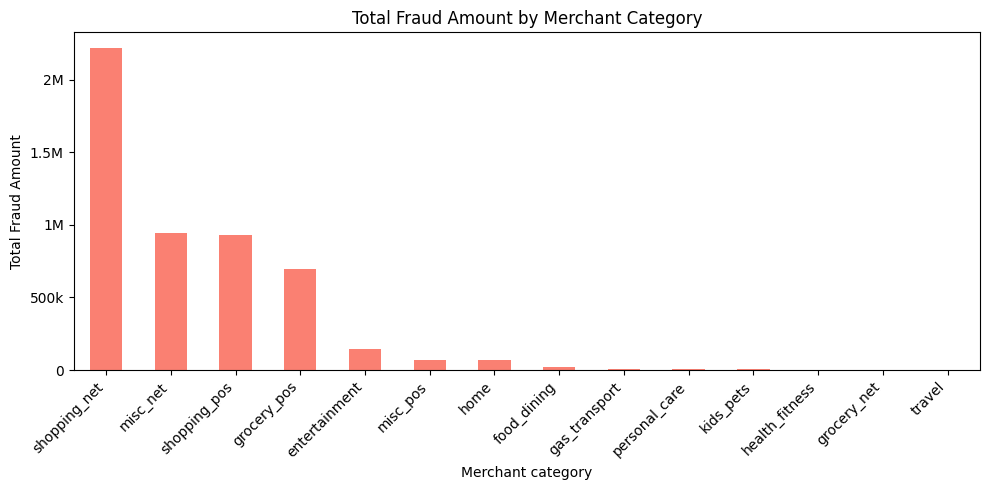

,total_fraud_amount
category,
shopping_net,2214847.64
misc_net,944009.71
shopping_pos,928132.34
grocery_pos,695664.62
entertainment,147399.96
misc_pos,68494.84
home,68231.96
food_dining,24739.16
gas_transport,9442.53


In [23]:
fraud_transactions = df.loc[df['is_fraud'] == 1]
valid_fraud_amount = fraud_transactions['category'].notna() & np.isfinite(fraud_transactions['amt'])

fraud_category_amount = (
    fraud_transactions.loc[valid_fraud_amount].groupby('category', observed=True)['amt']
    .sum().sort_values(ascending=False)
)

ax = fraud_category_amount.plot.bar(color='salmon', figsize=(10, 5))
ax.yaxis.set_major_formatter(plt.FuncFormatter(
    lambda value, _: f'{value / 1_000_000:g}M' if abs(value) >= 1_000_000
    else f'{value / 1_000:g}k' if abs(value) >= 1_000 else f'{value:g}'
))
plt.xlabel('Merchant category')
plt.ylabel('Total Fraud Amount')
plt.title('Total Fraud Amount by Merchant Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(fraud_category_amount.to_frame('total_fraud_amount'))


The analysis of total fraud losses confirms the dominance of online shopping, which accounts for the vast majority of overall financial impact, while most other categories contribute negligibly to total losses.

### Top Merchants by Fraud Count


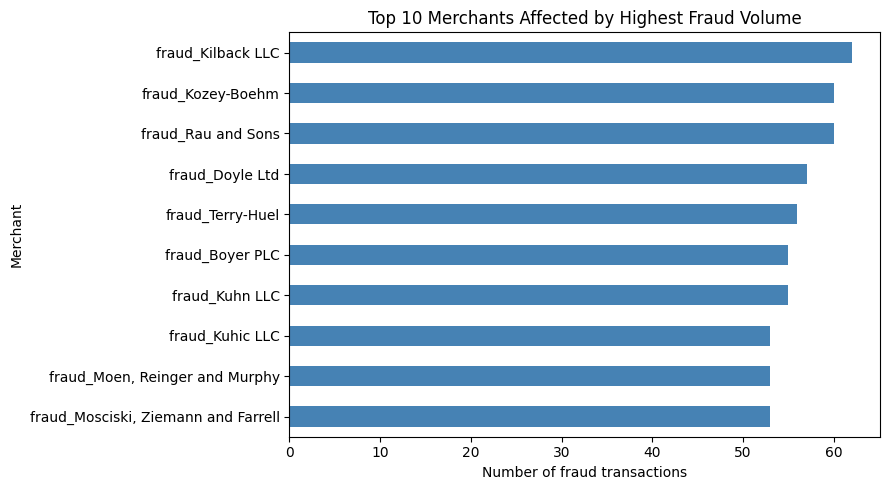

,merchant,total_transactions,fraud_transactions,fraud_rate_pct
0,fraud_Kilback LLC,6262,62,0.990099
1,fraud_Rau and Sons,3546,60,1.692047
2,fraud_Kozey-Boehm,2758,60,2.175489
3,fraud_Doyle Ltd,3502,57,1.627641
4,fraud_Terry-Huel,2864,56,1.955307
5,fraud_Kuhn LLC,5031,55,1.093222
6,fraud_Boyer PLC,4999,55,1.100220
7,"fraud_Mosciski, Ziemann and Farrell",2821,53,1.878766
8,"fraud_Moen, Reinger and Murphy",3393,53,1.562039
9,fraud_Kuhic LLC,2842,53,1.864884


In [24]:
merchant_stats = df.groupby('merchant', observed=True)['is_fraud'].agg(
    total_transactions='count', fraud_transactions='sum'
)
merchant_stats['fraud_rate_pct'] = merchant_stats['fraud_transactions'] / merchant_stats['total_transactions'] * 100
top_merchants = merchant_stats[merchant_stats['fraud_transactions'] > 0].sort_values(
    'fraud_transactions', ascending=False
).head(10)


top_merchants['fraud_transactions'].sort_values().plot.barh(color='steelblue', figsize=(9, 5))
plt.xlabel('Number of fraud transactions')
plt.ylabel('Merchant')
plt.title('Top 10 Merchants Affected by Highest Fraud Volume')
plt.tight_layout()
plt.show()

display(top_merchants.rename_axis('merchant').reset_index())


Looking at the most affected merchants, fraud volume is distributed relatively evenly across top entities without a single dominant merchant, suggesting that attackers are targeting multiple merchants at once rather than focusing on a single breached system.

### Time Since Previous Transaction


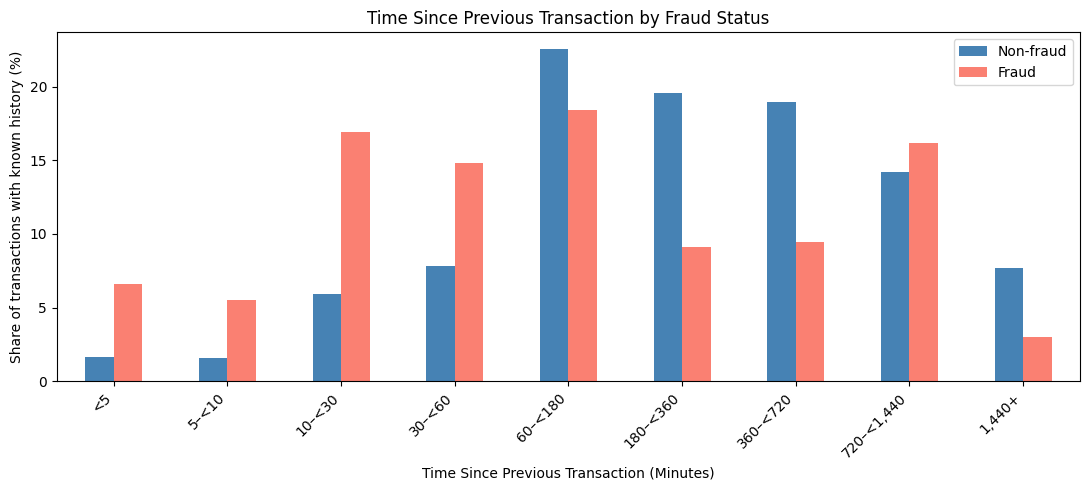

Transaction counts by time interval:


is_fraud,Non-fraud,Fraud
<5,30152,633
5–<10,29443,526
10–<30,109653,1618
30–<60,144565,1416
60–<180,415311,1762
180–<360,360222,871
360–<720,348848,906
"720–<1,440",261731,1543
"1,440+",141910,285


In [25]:
valid_history = df['cc_num'].notna() & df['trans_date_trans_time'].notna()
history = df.loc[valid_history, ['cc_num', 'trans_date_trans_time', 'is_fraud']].copy()
card_times = (
    history[['cc_num', 'trans_date_trans_time']].drop_duplicates()
    .sort_values(['cc_num', 'trans_date_trans_time'])
)
card_times['minutes_since_previous'] = (
    card_times.groupby('cc_num', observed=True)['trans_date_trans_time']
    .diff().dt.total_seconds() / 60
)
history = history.merge(card_times, on=['cc_num', 'trans_date_trans_time'], how='left', validate='many_to_one')

time_group = pd.cut(
    history['minutes_since_previous'],
    bins=[0, 5, 10, 30, 60, 180, 360, 720, 1440, np.inf],
    labels=['<5', '5–<10', '10–<30', '30–<60', '60–<180', '180–<360',
            '360–<720', '720–<1,440', '1,440+'],
    right=False,
)
time_counts = pd.crosstab(time_group, history['is_fraud']).reindex(
    index=time_group.cat.categories, columns=[0, 1], fill_value=0
)
time_percent = time_counts.div(time_counts.sum(axis=0).replace(0, np.nan), axis=1) * 100
time_percent.columns = ['Non-fraud', 'Fraud']

time_percent.plot.bar(color=['steelblue', 'salmon'], figsize=(11, 5))
plt.xlabel('Time Since Previous Transaction (Minutes)')
plt.ylabel('Share of transactions with known history (%)')
plt.title('Time Since Previous Transaction by Fraud Status')
plt.xticks(rotation=45, ha='right')
plt.legend(title='')
plt.tight_layout()
plt.show()

print('Transaction counts by time interval:')
display(time_counts.rename(columns={0: 'Non-fraud', 1: 'Fraud'}))


The time since previous transaction comparison shows a higher proportion of fraudulent payments within shorter time intervals, which may indicate a tendency toward more rapid consecutive attempts.

### Customer Age

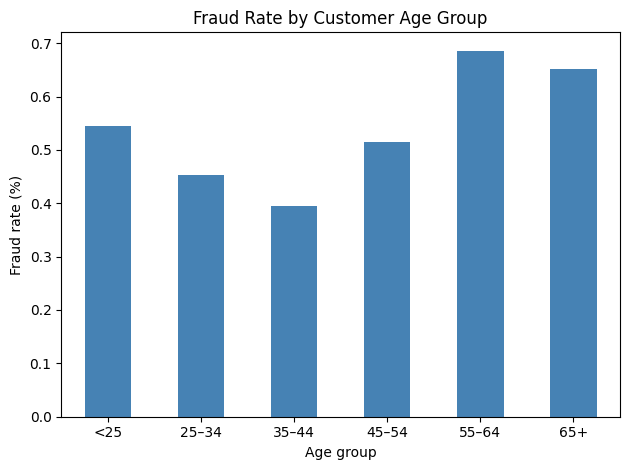

In [26]:
dob = pd.to_datetime(df['dob'], errors='coerce')
df['age'] = (df['trans_date_trans_time'] - dob).dt.days / 365.25

df['age_group'] = pd.cut(
    df['age'], bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=['<25', '25–34', '35–44', '45–54', '55–64', '65+'], right=False,
)

age_stats = df.groupby('age_group', observed=True)['is_fraud'].agg(['mean', 'count', 'sum'])
(age_stats['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Age group')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud Rate by Customer Age Group')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The risk rate shows moderate variability across age groups, with a slightly higher fraud concentration appearing in older age categories and among the youngest users.

### Customer City Size

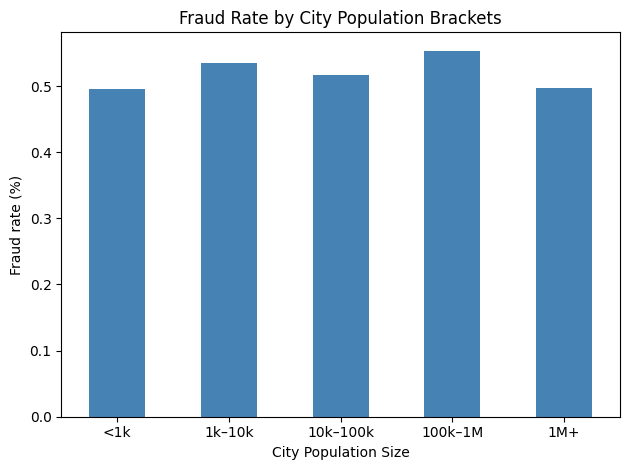

In [27]:
df['city_size'] = pd.cut(
    df['city_pop'], bins=[0, 1_000, 10_000, 100_000, 1_000_000, np.inf],
    labels=['<1k', '1k–10k', '10k–100k', '100k–1M', '1M+'], right=False,
)

city_stats = df.groupby('city_size', observed=True)['is_fraud'].agg(['mean', 'count', 'sum'])

(city_stats['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('City Population Size')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud Rate by City Population Brackets')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The fraud rate remains relatively consistent across different city population sizes, suggesting that city population alone does not significantly influence fraud risk.

# 5. Summary

Based on EDA findings, the feature engineering process focused primarily on capturing temporal dynamics, transaction frequency, and deviations from typical customer behavior. Since static attributes (such as geographic distance or demographics) showed limited standalone predictive power, they were transformed into comparative metrics, allowing the model to evaluate whether a transaction deviates from a customer's typical spending habits.